# Тесты и проверка LoRA-адаптеров: Countdown, GRPO + LoRA

Автор: А. Любошенко, студент магистратуры НИЯУ МИФИ.

Второй ноутбук проекта. Основной отчёт с графиками обучения и выводами - [`countdown_grpo.ipynb`](countdown_grpo.ipynb).
Здесь проверяется, что всё, на чём стоят выводы отчёта, работает так, как заявлено.

| Раздел | Что проверяется | Нужен GPU |
|---|---|---|
| 1 | окружение и версии | нет |
| 2 | проверяющий и обе функции награды на заранее описанных случаях | нет |
| 3 | данные: размеры, решаемость, нетривиальные цели, нет дублей и пересечений, генератор заново строит те же файлы | нет |
| 4 | сохранённые результаты: каждый ответ заново проходит проверяющий, итоговая таблица совпадает с README | нет |
| 5 | LoRA-адаптеры с Hugging Face (скачиваются в `adapters/` при первом запуске): контрольные суммы, повторная оценка на held-out и сравнение с ответами, сохранёнными во время обучения | желательно |
| 6 | наглядно: какие задачи решает каждая модель, ответы всех моделей на одних и тех же задачах, свои задачи | желательно |
| 7 | сводка всех тестов | нет |

Каждый тест получает итог `PASS` или `FAIL`. Итог `ВНИМАНИЕ` бывает только в разделе 5 без GPU (пояснение там).

Запуск из корня проекта (на GTX 1060 около 6 минут плюс 1-2 минуты на скачивание адаптеров при первом запуске,
без GPU разделы 5-6 идут на CPU на первых 30 задачах):

```bash
jupyter nbconvert --to notebook --execute --inplace countdown_tests.ipynb
```

## 1. Окружение

Если GPU есть, адаптеры оцениваются так же, как во время обучения: fp16, весь held-out (300 задач).
Без GPU используется CPU, fp32 и первые 30 задач held-out, иначе оценка 7 моделей займёт слишком много времени.

In [1]:
# Блок: импорты, версии и выбор устройства
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from src import analysis, config
from src.countdown_data import (assign_ids, generate_unique_tasks, is_trivial_target, load_jsonl,
                                split_tasks, task_key)
from src.evaluate import evaluate_tasks
from src.model_utils import load_model, load_tokenizer
from src.reward import check_answer, partial_closeness_reward, strict_binary_reward

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
transformers.logging.disable_progress_bar()   # без полос "Loading weights" при каждой загрузке модели

print("Python:", sys.version.split()[0])
print("torch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("transformers:", transformers.__version__, "| trl:", trl.__version__, "| peft:", peft.__version__)

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE_NAME = config.MODEL_DTYPE_NAME    # float16, как при обучении и оценке
    NUM_EVAL_TASKS = config.HELDOUT_SIZE   # весь held-out
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE_NAME = "float32"                  # на CPU fp16 медленный и не везде поддержан
    NUM_EVAL_TASKS = 30                     # на CPU только первые 30 задач held-out
    print("GPU не найден, разделы 5-6 пойдут на CPU")
print("Устройство:", DEVICE, "| dtype:", DTYPE_NAME, "| задач для оценки адаптеров:", NUM_EVAL_TASKS)

Python: 3.12.3
torch: 2.14.1+cu126 | CUDA: 12.6
transformers: 5.22.2 | trl: 1.17.1 | peft: 0.21.2
GPU: NVIDIA GeForce GTX 1060 6GB
Устройство: cuda | dtype: float16 | задач для оценки адаптеров: 300


In [2]:
# Блок: учёт результатов тестов (сводка в разделе 7)
TEST_RESULTS = []


def record_test(group, name, passed, details="", strict=True):
    """
    Запоминает итог одного теста. Печатает только непройденные, чтобы вывод не дублировал таблицы.
    strict=False: непройденный тест получает итог ВНИМАНИЕ, а не FAIL (только раздел 5 без GPU).
    """
    if passed:
        outcome = "PASS"
    elif strict:
        outcome = "FAIL"
    else:
        outcome = "ВНИМАНИЕ"
    TEST_RESULTS.append({"группа": group, "тест": name, "итог": outcome, "детали": details})
    if outcome != "PASS":
        print(outcome, "|", group, "|", name, "|", details)

## 2. Проверяющий и функции награды

Код: [`src/reward.py`](src/reward.py). Каждый случай описан заранее по правилам из задания:
какой статус проверки и какую награду должен получить ответ.

- Строгая награда (условие `baseline`): 1 только при статусе `correct`, иначе 0.
- Частичная награда (условие `partial`): 1 при `correct`, `0.5 * max(0, 1 - |значение - цель| / цель)` при `wrong_value`
  (выражение по всем правилам, но значение не равно цели), 0 при любом нарушении правил.

Функции награды вызываются так же, как их вызывает `GRPOTrainer`: списками ответов, чисел и целей.

In [3]:
# Блок: случаи для проверки
# Формат: (что проверяем, ответ модели, числа, цель, ожидаемый статус, ожидаемая частичная награда)
TIMES_SIGN = "×"     # знак умножения из условия задачи
DIVIDE_SIGN = "÷"    # знак деления из условия задачи
SUM_PARTIAL = 0.5 * (1 - 11 / 46)   # 25 + 7 + 3 = 35, ошибка 11 при цели 46

reward_cases = [
    ("верный ответ", "<answer>25 + 3 * 7</answer>", [3, 7, 25], 46, "correct", 1.0),
    ("верный ответ, другой порядок чисел", "<answer>7 * 3 + 25</answer>", [3, 7, 25], 46, "correct", 1.0),
    ("короткое рассуждение перед тегом", "3 * 7 = 21, 21 + 25 = 46. <answer>25 + 3 * 7</answer>",
     [3, 7, 25], 46, "correct", 1.0),
    ("знак умножения из условия", "<answer>25 + 3 " + TIMES_SIGN + " 7</answer>", [3, 7, 25], 46, "correct", 1.0),
    ("знак деления из условия", "<answer>40 + 6 " + DIVIDE_SIGN + " 2</answer>", [6, 2, 40], 43, "correct", 1.0),
    ("несколько тегов: проверяется последний (неверный)",
     "<answer>25 + 3 * 7</answer> <answer>25 + 7 + 3</answer>", [3, 7, 25], 46, "wrong_value", SUM_PARTIAL),
    ("несколько тегов: проверяется последний (верный)",
     "<answer>25 + 7 + 3</answer> <answer>25 + 3 * 7</answer>", [3, 7, 25], 46, "correct", 1.0),
    ("нет тегов answer", "25 + 3 * 7", [3, 7, 25], 46, "no_answer", 0.0),
    ("дописано = 46", "<answer>25 + 3 * 7 = 46</answer>", [3, 7, 25], 46, "forbidden_syntax", 0.0),
    ("в теге только цель", "<answer>46</answer>", [3, 7, 25], 46, "wrong_numbers", 0.0),
    ("число 7 повторено трижды, 3 пропущено", "<answer>25 + 7 + 7 + 7</answer>", [3, 7, 25], 46, "wrong_numbers", 0.0),
    ("пропущено число 4", "<answer>40 + 6</answer>", [4, 6, 40], 46, "wrong_numbers", 0.0),
    ("добавлено своё число 21", "<answer>25 + 21</answer>", [3, 7, 25], 46, "wrong_numbers", 0.0),
    ("склеены цифры 3 и 7 в 37", "<answer>37 + 9</answer>", [3, 7, 9], 46, "wrong_numbers", 0.0),
    ("возведение в степень", "<answer>38 + 2 ** 3</answer>", [2, 3, 38], 46, "forbidden_syntax", 0.0),
    ("унарный минус", "<answer>25 - -3 * 7</answer>", [3, 7, 25], 46, "forbidden_syntax", 0.0),
    ("дробная запись числа", "<answer>25 + 3.0 * 7</answer>", [3, 7, 25], 46, "forbidden_syntax", 0.0),
    ("код Python вместо выражения (не выполняется)", "<answer>__import__('os').getcwd()</answer>",
     [3, 7, 25], 46, "forbidden_syntax", 0.0),
    ("незакрытая скобка", "<answer>25 + (3 * 7</answer>", [3, 7, 25], 46, "parse_error", 0.0),
    ("деление на ноль", "<answer>3 / (5 - 5)</answer>", [5, 5, 3], 3, "division_by_zero", 0.0),
    ("точная арифметика: 13 / 3 * 27 = 117", "<answer>13 / 3 * 27</answer>", [13, 3, 27], 117, "correct", 1.0),
    ("частичная награда: сумма всех чисел", "<answer>25 + 7 + 3</answer>", [3, 7, 25], 46, "wrong_value", SUM_PARTIAL),
    ("частичная награда: значение дальше цели, чем на саму цель", "<answer>(25 - 3) * 7</answer>",
     [3, 7, 25], 46, "wrong_value", 0.0),
]
print("Случаев:", len(reward_cases))
print("Зачем нужна точная арифметика: во float 13 / 3 * 27 =", 13 / 3 * 27, "а не 117")

Случаев: 23
Зачем нужна точная арифметика: во float 13 / 3 * 27 = 116.99999999999999 а не 117


In [4]:
# Блок: прогон случаев через проверяющий и обе функции награды
reward_rows = []
for description, completion, numbers, target, expected_status, expected_partial in reward_cases:
    check = check_answer(completion, numbers, target)
    strict_reward = strict_binary_reward([completion], [numbers], [target])[0]
    partial_reward = partial_closeness_reward([completion], [numbers], [target])[0]
    if expected_status == "correct":
        expected_strict = 1.0
    else:
        expected_strict = 0.0
    passed = (check["status"] == expected_status
              and strict_reward == expected_strict
              and abs(partial_reward - expected_partial) < 1e-9)
    record_test("награда", description, passed, check["status"])
    reward_rows.append({
        "что проверяем": description,
        "ответ модели": completion,
        "числа -> цель": str(numbers) + " -> " + str(target),
        "статус": check["status"],
        "ожидался": expected_status,
        "строгая": strict_reward,
        "частичная": round(partial_reward, 3),
        "итог": "PASS" if passed else "FAIL",
    })

reward_table = pd.DataFrame(reward_rows)
print("Пройдено", (reward_table["итог"] == "PASS").sum(), "из", len(reward_table))
reward_table

Пройдено 23 из 23


,что проверяем,ответ модели,числа -> цель,статус,ожидался,строгая,частичная,итог
0,верный ответ,<answer>25 + 3 * 7</answer>,"[3, 7, 25] -> 46",correct,correct,1.0,1.00,PASS
1,"верный ответ, другой порядок чисел",<answer>7 * 3 + 25</answer>,"[3, 7, 25] -> 46",correct,correct,1.0,1.00,PASS
2,короткое рассуждение перед тегом,"3 * 7 = 21, 21 + 25 = 46. <answer>25 + 3 * 7</answer>","[3, 7, 25] -> 46",correct,correct,1.0,1.00,PASS
3,знак умножения из условия,<answer>25 + 3 × 7</answer>,"[3, 7, 25] -> 46",correct,correct,1.0,1.00,PASS
4,знак деления из условия,<answer>40 + 6 ÷ 2</answer>,"[6, 2, 40] -> 43",correct,correct,1.0,1.00,PASS
5,несколько тегов: проверяется последний (неверный),<answer>25 + 3 * 7</answer> <answer>25 + 7 + 3</answer>,"[3, 7, 25] -> 46",wrong_value,wrong_value,0.0,0.38,PASS
6,несколько тегов: проверяется последний (верный),<answer>25 + 7 + 3</answer> <answer>25 + 3 * 7</answer>,"[3, 7, 25] -> 46",correct,correct,1.0,1.00,PASS
7,нет тегов answer,25 + 3 * 7,"[3, 7, 25] -> 46",no_answer,no_answer,0.0,0.00,PASS
8,дописано = 46,<answer>25 + 3 * 7 = 46</answer>,"[3, 7, 25] -> 46",forbidden_syntax,forbidden_syntax,0.0,0.00,PASS
9,в теге только цель,<answer>46</answer>,"[3, 7, 25] -> 46",wrong_numbers,wrong_numbers,0.0,0.00,PASS


## 3. Данные

Код: [`src/countdown_data.py`](src/countdown_data.py), файлы: [`data/`](data/).
Проверяются требования задания к задачам: только решаемые задачи, без тривиальных целей (цель равна одному из чисел
или их сумме), без дублей, train и held-out не пересекаются, held-out не меньше 200 задач.
Последний тест заново запускает генератор с `DATA_SEED = 42` и сравнивает результат с файлами в `data/`.

In [5]:
# Блок: загрузка сплитов
train_tasks = load_jsonl(config.TRAIN_PATH)
val_tasks = load_jsonl(config.VAL_PATH)
heldout_tasks = load_jsonl(config.HELDOUT_PATH)
splits = {"train": train_tasks, "val": val_tasks, "held-out": heldout_tasks}
for split_name, tasks in splits.items():
    print(split_name, "задач:", len(tasks), "| пример:", tasks[0])

train задач: 3985 | пример: {'numbers': [16, 79, 2], 'target': 190, 'solution': '2 * (16 + 79)', 'id': 'train_0000'}
val задач: 200 | пример: {'numbers': [7, 77, 70], 'target': 1, 'solution': '(77 - 7) / 70', 'id': 'val_0000'}
held-out задач: 300 | пример: {'numbers': [25, 92, 73], 'target': 44, 'solution': '25 + (92 - 73)', 'id': 'heldout_0000'}


In [6]:
# Блок: тесты данных
sizes = (len(train_tasks), len(val_tasks), len(heldout_tasks))
record_test("данные", "held-out не меньше 200 задач (требование задания)", len(heldout_tasks) >= 200,
            str(len(heldout_tasks)) + " задач")
record_test("данные", "размеры сплитов 3985 / 200 / 300 (как в WORKLOG.MD)", sizes == (3985, 200, 300), str(sizes))

for split_name, tasks in splits.items():
    out_of_range = 0   # не 3 числа, число вне 1-99 или цель вне 1-199
    unsolved = 0       # эталонное решение не проходит проверяющий
    trivial = 0        # цель совпадает с одним из чисел или с их суммой
    for task in tasks:
        numbers = task["numbers"]
        target = task["target"]
        if len(numbers) != config.NUM_COUNT or min(numbers) < config.NUMBER_MIN or max(numbers) > config.NUMBER_MAX:
            out_of_range += 1
        if type(target) is not int or target < config.TARGET_MIN or target > config.TARGET_MAX:
            out_of_range += 1
        check = check_answer("<answer>" + task["solution"] + "</answer>", numbers, target)
        if check["status"] != "correct":
            unsolved += 1
        if is_trivial_target(numbers, target):
            trivial += 1
    keys = [task_key(task) for task in tasks]
    duplicates = len(keys) - len(set(keys))
    record_test("данные", split_name + ": числа и цель в заданных диапазонах", out_of_range == 0,
                "нарушений: " + str(out_of_range))
    record_test("данные", split_name + ": каждая задача решаема (эталон проходит проверку)", unsolved == 0,
                "не решено: " + str(unsolved))
    record_test("данные", split_name + ": нет тривиальных целей", trivial == 0, "тривиальных: " + str(trivial))
    record_test("данные", split_name + ": нет дублей", duplicates == 0, "дублей: " + str(duplicates))

# пересечения между сплитами по ключу задачи (отсортированные числа + цель)
key_sets = {}
for split_name, tasks in splits.items():
    key_sets[split_name] = set(task_key(task) for task in tasks)
for first, second in [("train", "val"), ("train", "held-out"), ("val", "held-out")]:
    common = len(key_sets[first] & key_sets[second])
    record_test("данные", "нет общих задач: " + first + " и " + second, common == 0, "общих: " + str(common))

# строже требования задания: в train нет даже того же набора чисел, что в val или held-out (с любой целью)
reserved_numbers = set(tuple(sorted(task["numbers"])) for task in val_tasks + heldout_tasks)
same_numbers = 0
for task in train_tasks:
    if tuple(sorted(task["numbers"])) in reserved_numbers:
        same_numbers += 1
record_test("данные", "в train нет наборов чисел из val и held-out", same_numbers == 0, "совпадений: " + str(same_numbers))

all_ids = []
for tasks in splits.values():
    for task in tasks:
        all_ids.append(task["id"])
record_test("данные", "id задач уникальны", len(all_ids) == len(set(all_ids)), str(len(all_ids)) + " id")

data_table = pd.DataFrame([row for row in TEST_RESULTS if row["группа"] == "данные"])
data_table

,группа,тест,итог,детали
0,данные,held-out не меньше 200 задач (требование задания),PASS,300 задач
1,данные,размеры сплитов 3985 / 200 / 300 (как в WORKLOG.MD),PASS,"(3985, 200, 300)"
2,данные,train: числа и цель в заданных диапазонах,PASS,нарушений: 0
3,данные,train: каждая задача решаема (эталон проходит проверку),PASS,не решено: 0
4,данные,train: нет тривиальных целей,PASS,тривиальных: 0
5,данные,train: нет дублей,PASS,дублей: 0
6,данные,val: числа и цель в заданных диапазонах,PASS,нарушений: 0
7,данные,val: каждая задача решаема (эталон проходит проверку),PASS,не решено: 0
8,данные,val: нет тривиальных целей,PASS,тривиальных: 0
9,данные,val: нет дублей,PASS,дублей: 0


In [7]:
# Блок: генератор с DATA_SEED = 42 заново строит те же самые задачи (несколько секунд)
regenerated = generate_unique_tasks(
    total_count=config.TRAIN_SIZE + config.VAL_SIZE + config.HELDOUT_SIZE,
    seed=config.DATA_SEED,
    num_count=config.NUM_COUNT,
    number_min=config.NUMBER_MIN,
    number_max=config.NUMBER_MAX,
    target_min=config.TARGET_MIN,
    target_max=config.TARGET_MAX,
)
new_train, new_val, new_heldout = split_tasks(regenerated, config.HELDOUT_SIZE, config.VAL_SIZE, config.DATA_SEED)
assign_ids(new_train, "train")
assign_ids(new_val, "val")
assign_ids(new_heldout, "heldout")

same_data = new_train == train_tasks and new_val == val_tasks and new_heldout == heldout_tasks
record_test("данные", "генератор с DATA_SEED = 42 строит те же файлы", same_data,
            "train/val/held-out совпали" if same_data else "есть отличия")
print("Совпадение с файлами data/:", same_data)

Сгенерировано задач: 4500 | попыток: 32390
Убрано из train задач с набором чисел из val/held-out: 15
Пересечений между train / val / held-out нет
Совпадение с файлами data/: True


## 4. Сохранённые результаты

Файлы: [`results/`](results/). Во время обучения каждые 25 шагов модель отвечала на все 300 задач held-out,
ответы сохранены в `results/<запуск>/heldout_answers/`, ответы базы - в `results/eval/heldout_base_answers.jsonl`.
Здесь проверяется:
- все 6 запусков завершены, в логах нет пропущенных шагов
- каждый сохранённый ответ заново проходит текущий проверяющий и получает тот же статус и ту же награду
- итоговая точность, пересчитанная из ответов, совпадает с таблицей в `README.md`

In [8]:
# Блок: запуски и опубликованные числа (README.md, раздел "Результаты", точность в процентах)
RUNS = ["baseline_seed0", "baseline_seed1", "baseline_seed2", "partial_seed0", "partial_seed1", "partial_seed2"]
REPORTED_ACCURACY = {
    "base": 20.3,
    "baseline_seed0": 64.0, "baseline_seed1": 62.0, "baseline_seed2": 51.7,
    "partial_seed0": 56.7, "partial_seed1": 62.7, "partial_seed2": 57.7,
}
REPORTED_MEAN_STD = {"baseline": (59.2, 5.4), "partial": (59.0, 2.6)}

for run in RUNS:
    steps = list(analysis.load_train_log(run)["step"])
    eval_steps = list(analysis.load_eval_curve(run)["step"])
    record_test("результаты", run + ": запуск завершён (DONE.json)", analysis.run_is_done(run))
    record_test("результаты", run + ": в логе обучения шаги 1-150 без пропусков", steps == list(range(1, 151)),
                str(len(steps)) + " шагов")
    record_test("результаты", run + ": оценка held-out на шагах 0, 25, ..., 150",
                eval_steps == [0, 25, 50, 75, 100, 125, 150], str(eval_steps))

In [9]:
# Блок: каждый сохранённый ответ заново проходит проверяющий
answer_files = [os.path.join(config.RESULTS_DIR, "eval", "heldout_base_answers.jsonl")]
for run in RUNS:
    folder = os.path.join(config.RESULTS_DIR, run, "heldout_answers")
    for file_name in sorted(os.listdir(folder)):
        if file_name.endswith("_answers.jsonl"):
            answer_files.append(os.path.join(folder, file_name))

checked = 0
mismatched = 0
for path in answer_files:
    for record in analysis.read_jsonl(path):
        check = check_answer(record["completion"], record["numbers"], record["target"])
        checked += 1
        if check["status"] != record["status"] or check["reward"] != record["reward"]:
            mismatched += 1
print("Файлов:", len(answer_files), "| ответов:", checked, "| расхождений:", mismatched)
record_test("результаты", "сохранённые ответы заново проверены: статус и награда те же", mismatched == 0,
            str(checked) + " ответов, расхождений " + str(mismatched))

Файлов: 37 | ответов: 11100 | расхождений: 0


In [10]:
# Блок: итоговая точность из сохранённых ответов против таблицы в README.md
final_rows = []
for name in ["base"] + RUNS:
    if name == "base":
        step = 0
    else:
        step = 150
    records = analysis.load_answers(name, step)
    num_correct = 0
    for record in records:
        if record["status"] == "correct":
            num_correct += 1
    accuracy = 100 * num_correct / len(records)
    matches = round(accuracy, 1) == REPORTED_ACCURACY[name]
    record_test("результаты", name + ": точность совпадает с README.md", matches,
                str(round(accuracy, 1)) + "% против " + str(REPORTED_ACCURACY[name]) + "%")
    final_rows.append({"модель": name, "шаг": step, "верно": num_correct, "задач": len(records),
                       "точность, %": round(accuracy, 1), "в README, %": REPORTED_ACCURACY[name]})

final_table = pd.DataFrame(final_rows)

# среднее и разброс по seed (std по трём seed, как в основном ноутбуке)
for condition, (reported_mean, reported_std) in REPORTED_MEAN_STD.items():
    values = final_table[final_table["модель"].str.startswith(condition)]["точность, %"].to_numpy()
    mean_value = round(float(np.mean(values)), 1)
    std_value = round(float(np.std(values)), 1)
    record_test("результаты", condition + ": среднее и std по seed совпадают с README.md",
                (mean_value, std_value) == (reported_mean, reported_std),
                str(mean_value) + " +- " + str(std_value))
    print(condition, "| среднее", mean_value, "| std", std_value)

final_table

baseline | среднее 59.2 | std 5.4
partial | среднее 59.0 | std 2.6


,модель,шаг,верно,задач,"точность, %","в README, %"
0,base,0,61,300,20.3,20.3
1,baseline_seed0,150,192,300,64.0,64.0
2,baseline_seed1,150,186,300,62.0,62.0
3,baseline_seed2,150,155,300,51.7,51.7
4,partial_seed0,150,170,300,56.7,56.7
5,partial_seed1,150,188,300,62.7,62.7
6,partial_seed2,150,173,300,57.7,57.7


## 5. LoRA-адаптеры: повторная оценка на held-out

Адаптеры хранятся на Hugging Face: [liuboshenko/qwen3-0.6b-countdown-grpo-lora](https://huggingface.co/liuboshenko/qwen3-0.6b-countdown-grpo-lora),
по одному итоговому адаптеру (шаг 150) на каждый запуск. Адаптер - это только обученная надстройка (около 40 МБ),
базовая модель `Qwen/Qwen3-0.6B` скачивается с HuggingFace по зафиксированной ревизии (`MODEL_REVISION` в [`src/config.py`](src/config.py)).

Если локальной папки `adapters/` нет (репозиторий склонирован с GitHub), первая ячейка раздела скачивает адаптеры
по зафиксированному коммиту (около 243 МБ) и проверяет контрольные суммы SHA256 всех файлов.

Каждая модель загружается заново и отвечает на задачи held-out той же процедурой, что во время обучения:
жадное декодирование, тот же промпт, тот же размер батча, та же проверка ([`src/evaluate.py`](src/evaluate.py)).
Затем ответы сравниваются с сохранёнными в `results/` на шаге 150 (для базы - с ответами до обучения).

Строгое совпадение ожидается на GPU в fp16, как у автора (GTX 1060). На CPU (fp32) и на другой видеокарте
порядок округлений другой, поэтому при жадном декодировании отдельные ответы могут отличаться.
Без GPU расхождение получает итог `ВНИМАНИЕ`, а не `FAIL`.

In [11]:
# Блок: адаптеры с Hugging Face. Если локальной копии нет, скачиваем её по зафиксированному коммиту
import hashlib

from huggingface_hub import snapshot_download

HF_ADAPTERS_REPO = "liuboshenko/qwen3-0.6b-countdown-grpo-lora"
HF_ADAPTERS_REVISION = "810b01b87a5fc33b32dcadfa7f15153fb620cfdd"   # коммит, на котором выложены адаптеры
ADAPTERS_DIR = "adapters"   # путь от корня проекта (ноутбук запускается из корня)

missing_runs = []
for run in RUNS:
    if not os.path.exists(os.path.join(ADAPTERS_DIR, run, "adapter_model.safetensors")):
        missing_runs.append(run)
if len(missing_runs) > 0 or not os.path.exists(os.path.join(ADAPTERS_DIR, "SHA256SUMS.txt")):
    print("Локальных адаптеров нет:", missing_runs, "| скачиваем с Hugging Face:", HF_ADAPTERS_REPO)
    start_time = time.time()
    snapshot_download(repo_id=HF_ADAPTERS_REPO, revision=HF_ADAPTERS_REVISION, local_dir=ADAPTERS_DIR)
    print("Скачано за, сек:", round(time.time() - start_time, 1))
else:
    print("Адаптеры уже есть локально в папке", ADAPTERS_DIR)

# контрольные суммы: файлы те же, на которых получены результаты отчёта
with open(os.path.join(ADAPTERS_DIR, "SHA256SUMS.txt"), encoding="utf-8") as sums_file:
    for line in sums_file:
        line = line.strip()
        if line == "":
            continue
        expected_hash, file_name = line.split()
        with open(os.path.join(ADAPTERS_DIR, file_name), "rb") as adapter_file:
            actual_hash = hashlib.sha256(adapter_file.read()).hexdigest()
        record_test("адаптеры", file_name + ": контрольная сумма SHA256", actual_hash == expected_hash, actual_hash[:12])
print("Проверено контрольных сумм:", len([row for row in TEST_RESULTS if "SHA256" in row["тест"]]))

Локальных адаптеров нет: ['baseline_seed0', 'baseline_seed1', 'baseline_seed2', 'partial_seed0', 'partial_seed1', 'partial_seed2'] | скачиваем с Hugging Face: liuboshenko/qwen3-0.6b-countdown-grpo-lora


Скачано за, сек: 80.1


Проверено контрольных сумм: 12


In [12]:
# Блок: список моделей: база и адаптеры из папки adapters/
model_list = [("base", None)]
for run in RUNS:
    adapter_path = os.path.join(ADAPTERS_DIR, run)
    if os.path.exists(os.path.join(adapter_path, "adapter_model.safetensors")):
        model_list.append((run, adapter_path))
    else:
        print("Адаптер не найден, пропускаем:", adapter_path)

eval_tasks = heldout_tasks[:NUM_EVAL_TASKS]
tokenizer = load_tokenizer()
STRICT_ADAPTER_TESTS = DEVICE == "cuda"
print("Моделей:", len(model_list), "| задач:", len(eval_tasks), "| строгое сравнение:", STRICT_ADAPTER_TESTS)

Моделей: 7 | задач: 300 | строгое сравнение: True


In [13]:
# Блок: повторная оценка каждой модели и сравнение с сохранёнными ответами
new_answers = {}      # имя модели -> ответы на eval_tasks (нужны в разделе 6)
adapter_rows = []
section_start = time.time()

for name, adapter_path in model_list:
    start_time = time.time()
    model = load_model(adapter_path=adapter_path, dtype_name=DTYPE_NAME, device=DEVICE)
    records, summary = evaluate_tasks(model, tokenizer, eval_tasks)
    seconds = time.time() - start_time
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    new_answers[name] = records

    if name == "base":
        saved_step = 0
    else:
        saved_step = 150
    saved_records = analysis.load_answers(name, saved_step)[:len(eval_tasks)]
    same_text = 0
    saved_correct = 0
    for new_record, saved_record in zip(records, saved_records):
        if new_record["completion"] == saved_record["completion"]:
            same_text += 1
        if saved_record["status"] == "correct":
            saved_correct += 1
    new_correct = summary["num_correct"]

    record_test("адаптеры", name + ": точность совпала с сохранённой", new_correct == saved_correct,
                str(new_correct) + " против " + str(saved_correct) + " верных", strict=STRICT_ADAPTER_TESTS)
    record_test("адаптеры", name + ": ответы совпали дословно", same_text == len(eval_tasks),
                str(same_text) + " из " + str(len(eval_tasks)), strict=STRICT_ADAPTER_TESTS)
    print(name, "| верно сейчас:", new_correct, "| сохранено:", saved_correct,
          "| ответов совпало:", same_text, "из", len(eval_tasks), "| секунд:", round(seconds, 1))
    adapter_rows.append({
        "модель": name,
        "сохранено, %": round(100 * saved_correct / len(eval_tasks), 1),
        "пересчитано, %": round(100 * new_correct / len(eval_tasks), 1),
        "ответов совпало": str(same_text) + " / " + str(len(eval_tasks)),
        "секунд": round(seconds, 1),
    })

print("Время раздела, мин:", round((time.time() - section_start) / 60, 1))
adapter_table = pd.DataFrame(adapter_rows)
adapter_table

base | верно сейчас: 61 | сохранено: 61 | ответов совпало: 300 из 300 | секунд: 33.3


Загружен LoRA-адаптер: adapters/baseline_seed0


baseline_seed0 | верно сейчас: 192 | сохранено: 192 | ответов совпало: 300 из 300 | секунд: 44.6


Загружен LoRA-адаптер: adapters/baseline_seed1


baseline_seed1 | верно сейчас: 186 | сохранено: 186 | ответов совпало: 300 из 300 | секунд: 45.1


Загружен LoRA-адаптер: adapters/baseline_seed2


... (4 outputs left out)

partial_seed1 | верно сейчас: 188 | сохранено: 188 | ответов совпало: 300 из 300 | секунд: 45.0


Загружен LoRA-адаптер: adapters/partial_seed2


partial_seed2 | верно сейчас: 173 | сохранено: 173 | ответов совпало: 300 из 300 | секунд: 44.9
Время раздела, мин: 5.0


,модель,"сохранено, %","пересчитано, %",ответов совпало,секунд
0,base,20.3,20.3,300 / 300,33.3
1,baseline_seed0,64.0,64.0,300 / 300,44.6
2,baseline_seed1,62.0,62.0,300 / 300,45.1
3,baseline_seed2,51.7,51.7,300 / 300,44.2
4,partial_seed0,56.7,56.7,300 / 300,44.9
5,partial_seed1,62.7,62.7,300 / 300,45.0
6,partial_seed2,57.7,57.7,300 / 300,44.9


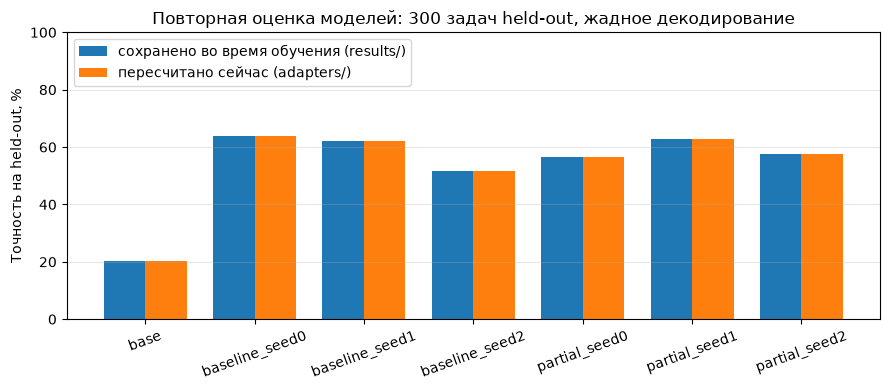

In [14]:
# Блок: график: точность, сохранённая во время обучения, и пересчитанная сейчас
figure, axis = plt.subplots(figsize=(9, 4))
positions = np.arange(len(adapter_table))
width = 0.38
axis.bar(positions - width / 2, adapter_table["сохранено, %"], width, label="сохранено во время обучения (results/)")
axis.bar(positions + width / 2, adapter_table["пересчитано, %"], width, label="пересчитано сейчас (adapters/)")
axis.set_xticks(positions)
axis.set_xticklabels(adapter_table["модель"], rotation=20)
axis.set_ylim(0, 100)
axis.set_ylabel("Точность на held-out, %")
axis.set_title("Повторная оценка моделей: " + str(len(eval_tasks)) + " задач held-out, жадное декодирование")
axis.legend(loc="upper left")
axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Наглядно: что решают модели

Все данные этого раздела - ответы, только что полученные в разделе 5 (кроме 6.3, где модели отвечают на свои задачи).

### 6.1. Какие задачи held-out решает каждая модель

Каждый столбец - одна задача, каждая строка - модель. Задачи отсортированы по числу обученных моделей,
которые их решают: слева задачи, решённые всеми шестью, справа - не решённые ни одной.

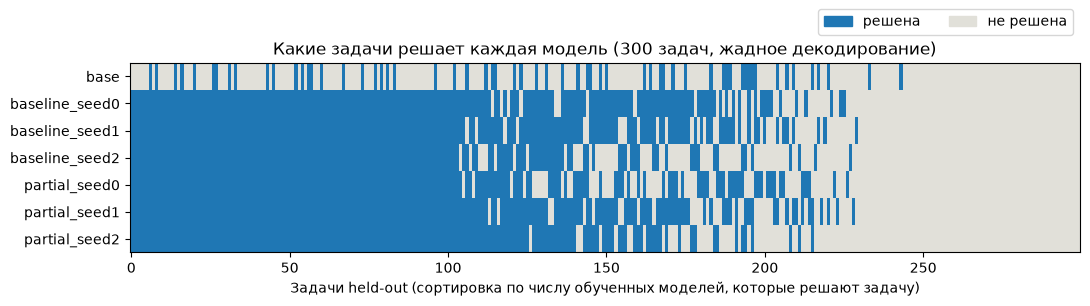

Задач: 300
Решены всеми 6 обученными моделями: 104
Не решены ни одной обученной моделью: 70
Решены базой: 61 | из них не решены ни одной обученной: 2


In [15]:
# Блок: карта "модель x задача": решена или нет
model_names = list(new_answers.keys())
correct_matrix = []
for name in model_names:
    row = []
    for record in new_answers[name]:
        row.append(1 if record["status"] == "correct" else 0)
    correct_matrix.append(row)
correct_matrix = np.array(correct_matrix)

# сортировка задач по числу обученных моделей, которые их решают (база в сортировке не участвует)
solved_by_trained = correct_matrix[1:].sum(axis=0)
order = np.argsort(-solved_by_trained, kind="stable")
num_trained = len(model_names) - 1

COLOR_SOLVED = "#1f77b4"
COLOR_UNSOLVED = "#e1e0d9"
figure, axis = plt.subplots(figsize=(11, 3.4))
axis.imshow(correct_matrix[:, order], aspect="auto", interpolation="nearest",
            cmap=ListedColormap([COLOR_UNSOLVED, COLOR_SOLVED]), vmin=0, vmax=1)
axis.set_yticks(range(len(model_names)))
axis.set_yticklabels(model_names)
axis.set_xlabel("Задачи held-out (сортировка по числу обученных моделей, которые решают задачу)")
axis.set_title("Какие задачи решает каждая модель (" + str(len(eval_tasks)) + " задач, жадное декодирование)")
axis.legend(handles=[Patch(color=COLOR_SOLVED, label="решена"), Patch(color=COLOR_UNSOLVED, label="не решена")],
            loc="upper right", bbox_to_anchor=(1.0, 1.32), ncol=2)
plt.tight_layout()
plt.show()

print("Задач:", len(eval_tasks))
print("Решены всеми", num_trained, "обученными моделями:", int((solved_by_trained == num_trained).sum()))
print("Не решены ни одной обученной моделью:", int((solved_by_trained == 0).sum()))
print("Решены базой:", int(correct_matrix[0].sum()),
      "| из них не решены ни одной обученной:", int(((correct_matrix[0] == 1) & (solved_by_trained == 0)).sum()))

### 6.2. Ответы всех моделей на одних и тех же задачах

По две задачи трёх видов: база ошиблась, а все обученные модели решили. Ни одна обученная модель не решила.
Обученные модели разошлись. Пометка `[+]` - ответ верный, `[-]` - неверный (со значением выражения или статусом проверки).

In [16]:
# Блок: таблица ответов на выбранные задачи
def short_answer(record):
    """Выражение из ответа модели и пометка о верности."""
    expression = record["expression"]
    if expression is None:
        expression = "(нет выражения)"
    if record["status"] == "correct":
        return expression + "  [+]"
    if record["status"] == "wrong_value":
        return expression + " = " + record["value"] + "  [-]"
    return expression + "  [-] " + record["status"]


task_kinds = [
    ("база ошиблась, все обученные решили", (correct_matrix[0] == 0) & (solved_by_trained == num_trained)),
    ("никто из обученных не решил", solved_by_trained == 0),
    ("обученные модели разошлись", (solved_by_trained > 0) & (solved_by_trained < num_trained)),
]
picked = []
for kind, mask in task_kinds:
    indices = list(np.where(mask)[0][:2])
    print(kind, "| задач такого вида:", int(mask.sum()), "| показаны:", [eval_tasks[i]["id"] for i in indices])
    for index in indices:
        picked.append(index)

answers_table = {}
for index in picked:
    task = eval_tasks[index]
    column = ", ".join(str(number) for number in task["numbers"]) + " -> " + str(task["target"])
    answers_table[column] = [short_answer(new_answers[name][index]) for name in model_names]
answers_table = pd.DataFrame(answers_table, index=model_names)
answers_table

база ошиблась, все обученные решили | задач такого вида: 80 | показаны: ['heldout_0000', 'heldout_0004']
никто из обученных не решил | задач такого вида: 70 | показаны: ['heldout_0002', 'heldout_0012']
обученные модели разошлись | задач такого вида: 126 | показаны: ['heldout_0001', 'heldout_0003']


,"25, 92, 73 -> 44","98, 3, 95 -> 6","13, 51, 44 -> 91","42, 18, 21 -> 49","30, 78, 7 -> 101","44, 29, 46 -> 27"
base,92 + 73 - 25 = 140 [-],95 + 3 [-] wrong_numbers,51 + 44 - 13 = 82 [-],21 + 21 [-] wrong_numbers,78 + 3 * 7 [-] wrong_numbers,46 + 29 - 44 = 31 [-]
baseline_seed0,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 - 13 = 82 [-],42 + 21 - 18 = 45 [-],78 + 30 - 7 [+],46 - 44 + 29 = 31 [-]
baseline_seed1,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 - 13 = 82 [-],42 + 21 - 18 = 45 [-],78 + 30 - 7 [+],44 - 46 + 29 [+]
baseline_seed2,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 - 13 = 82 [-],42 + 21 - 18 = 45 [-],78 - 30 + 7 = 55 [-],46 - 44 + 29 = 31 [-]
partial_seed0,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 - 13 = 82 [-],42 + 21 - 18 = 45 [-],78 + 30 - 7 [+],44 - 46 + 29 [+]
partial_seed1,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 - 13 = 82 [-],42 + 21 - 18 = 45 [-],78 + 30 - 7 [+],46 - 44 + 29 = 31 [-]
partial_seed2,92 - 73 + 25 [+],98 - 95 + 3 [+],51 + 44 + 13 = 108 [-],42 + 21 - 18 = 45 [-],78 + 30 - 7 [+],46 - 44 + 29 = 31 [-]


### 6.3. Свои задачи

Сюда можно вписать любые числа и цель и посмотреть, что ответят модели. Это демонстрация, а не оценка:
выводы в отчёте сделаны только по held-out. Ниже для примера две задачи, которые решаются сложением и вычитанием,
и две, где нужны умножение или деление (в основном ноутбуке, раздел 10, показано, что такие задачи модели
почти не решают).

In [17]:
# Блок: свои задачи (каждая решаема, решение в комментарии)
DEMO_TASKS = [
    {"id": "demo_0", "numbers": [44, 19, 7], "target": 56},   # 44 + 19 - 7
    {"id": "demo_1", "numbers": [83, 12, 35], "target": 60},  # 83 + 12 - 35
    {"id": "demo_2", "numbers": [8, 6, 50], "target": 98},    # 50 + 8 * 6
    {"id": "demo_3", "numbers": [12, 4, 9], "target": 27},    # 12 / 4 * 9
]

# проверка, что задачи решаемы и не взяты из train или held-out
all_keys = key_sets["train"] | key_sets["val"] | key_sets["held-out"]
for task in DEMO_TASKS:
    print(task["id"], task["numbers"], "->", task["target"], "| есть в данных проекта:", task_key(task) in all_keys)

demo_answers = {}
for name, adapter_path in model_list:
    model = load_model(adapter_path=adapter_path, dtype_name=DTYPE_NAME, device=DEVICE)
    records, summary = evaluate_tasks(model, tokenizer, DEMO_TASKS)
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    demo_answers[name] = [short_answer(record) for record in records]

demo_columns = []
for task in DEMO_TASKS:
    demo_columns.append(", ".join(str(number) for number in task["numbers"]) + " -> " + str(task["target"]))
demo_table = pd.DataFrame(demo_answers, index=demo_columns).T
demo_table

demo_0 [44, 19, 7] -> 56 | есть в данных проекта: False
demo_1 [83, 12, 35] -> 60 | есть в данных проекта: False
demo_2 [8, 6, 50] -> 98 | есть в данных проекта: False
demo_3 [12, 4, 9] -> 27 | есть в данных проекта: False


Загружен LoRA-адаптер: adapters/baseline_seed0


Загружен LoRA-адаптер: adapters/baseline_seed1


Загружен LoRA-адаптер: adapters/baseline_seed2


Загружен LoRA-адаптер: adapters/partial_seed0


Загружен LoRA-адаптер: adapters/partial_seed1


Загружен LoRA-адаптер: adapters/partial_seed2


,"44, 19, 7 -> 56","83, 12, 35 -> 60","8, 6, 50 -> 98","12, 4, 9 -> 27"
base,19 + 7 * 44 = 327 [-],35 + 12 [-] wrong_numbers,50 + 6 * 8 [+],9 + 4 * 12 = 57 [-]
baseline_seed0,44 + 19 - 7 [+],83 - 35 + 12 [+],50 + 8 - 6 = 52 [-],9 + 12 - 4 = 17 [-]
baseline_seed1,44 + 19 - 7 [+],83 - 35 + 12 [+],50 + 8 - 6 = 52 [-],9 + 12 - 4 = 17 [-]
baseline_seed2,44 + 19 - 7 [+],83 - 35 + 12 [+],50 + 8 - 6 = 52 [-],12 + 9 * 4 = 48 [-]
partial_seed0,44 + 19 - 7 [+],83 - 35 + 12 [+],8 + 50 + 6 = 64 [-],9 + 12 + 4 = 25 [-]
partial_seed1,44 + 19 - 7 [+],83 - 35 + 12 [+],50 + 8 * 6 [+],9 * 12 - 4 = 104 [-]
partial_seed2,44 + 19 - 7 [+],83 - 35 + 12 [+],50 + 8 + 6 = 64 [-],12 * 9 - 4 = 104 [-]


## 7. Сводка тестов

In [18]:
# Блок: сводка по группам тестов
summary_table = pd.DataFrame(TEST_RESULTS)
OUTCOMES = ["PASS", "ВНИМАНИЕ", "FAIL"]
GROUPS = ["награда", "данные", "результаты", "адаптеры"]
counts = summary_table.groupby(["группа", "итог"]).size().unstack(fill_value=0)
for outcome in OUTCOMES:
    if outcome not in counts.columns:
        counts[outcome] = 0
counts = counts.reindex(GROUPS).fillna(0).astype(int)[OUTCOMES]
counts["всего"] = counts.sum(axis=1)
print("Всего тестов:", len(summary_table), "| PASS:", int(counts["PASS"].sum()),
      "| ВНИМАНИЕ:", int(counts["ВНИМАНИЕ"].sum()), "| FAIL:", int(counts["FAIL"].sum()))
counts

Всего тестов: 97 | PASS: 97 | ВНИМАНИЕ: 0 | FAIL: 0


итог,PASS,ВНИМАНИЕ,FAIL,всего
группа,,,,
награда,23,0,0,23
данные,20,0,0,20
результаты,28,0,0,28
адаптеры,26,0,0,26


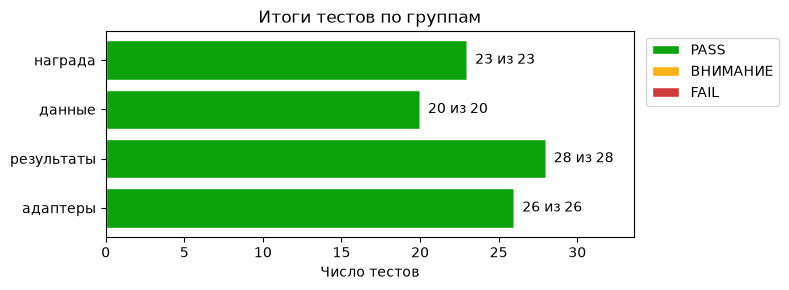

Все тесты пройдены


,группа,тест,итог,детали


In [19]:
# Блок: график итогов по группам тестов
OUTCOME_COLORS = {"PASS": "#0ca30c", "ВНИМАНИЕ": "#fab219", "FAIL": "#d03b3b"}
figure, axis = plt.subplots(figsize=(8, 3))
left = np.zeros(len(counts))
for outcome in OUTCOMES:
    values = counts[outcome].to_numpy()
    axis.barh(counts.index, values, left=left, color=OUTCOME_COLORS[outcome], label=outcome,
              edgecolor="white", linewidth=1)
    left = left + values
for position, group in enumerate(counts.index):
    label = str(counts.loc[group, "PASS"]) + " из " + str(counts.loc[group, "всего"])
    axis.text(counts.loc[group, "всего"] + 0.5, position, label, va="center")
axis.invert_yaxis()
axis.set_xlim(0, counts["всего"].max() * 1.2)
axis.set_xlabel("Число тестов")
axis.set_title("Итоги тестов по группам")
axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

not_passed = summary_table[summary_table["итог"] != "PASS"]
if len(not_passed) == 0:
    print("Все тесты пройдены")
else:
    print("Не пройдено:", len(not_passed))
not_passed

### Итог (прогон на машине автора: GTX 1060, fp16)

- Всего 97 тестов, все `PASS`: награда 23, данные 20, сохранённые результаты 28, адаптеры 26. Прогон около 6 минут
  плюс 80 секунд на скачивание адаптеров с Hugging Face (без токена, как у любого читателя).
- **Проверяющий** ведёт себя по правилам задания во всех 23 случаях, включая лазейки из задания
  (`= 46` в конце, только цель в теге, несколько тегов, повтор и пропуск чисел, склейка цифр) и защиту от выполнения кода.
- **Данные**: требования задания выполнены, генератор с `DATA_SEED = 42` строит те же файлы, что лежат в `data/`.
- **Результаты**: 11100 сохранённых ответов заново проверены, расхождений нет. Таблица в README совпадает с файлами.
- **Адаптеры**: скачаны с Hugging Face по зафиксированному коммиту, контрольные суммы SHA256 всех 12 файлов совпали.
  Все 7 моделей (база и 6 адаптеров) при повторной оценке дали дословно те же ответы,
  что были сохранены во время обучения, 300 из 300 у каждой. Значит, итоговая таблица отчёта получена именно этими адаптерами.
- **Что видно на карте задач (6.1)**: 104 задачи из 300 решают все 6 обученных моделей, 70 не решает ни одна.
  Из 61 задачи, решённой базой, только 2 не решает ни одна обученная модель.
- **Свои задачи (6.3)**: задачи на сложение и вычитание решают все обученные модели. Задачу 8, 6, 50 -> 98
  (нужно умножение) база решает, а из обученных только `partial_seed1`, остальные отвечают одними `+` и `-`.
  Это иллюстрирует вывод основного отчёта: обучение научило модель подбирать знаки сложения и вычитания,
  а умножение и деление модель почти перестала использовать.